# Dá Pra Ir? | Inteligência Artificial & Machine Learning

Global Solution FIAP 2026, tema CitizenTech.

## 1. Problema e pergunta de ML

O Dá Pra Ir? ajuda pessoas com deficiência, pessoas autistas e famílias atípicas a saber, antes de sair de casa, se um lugar vai funcionar para elas. Nosso recorte é a Vila Clementino (subprefeitura Vila Mariana), em São Paulo, onde ficam a AACD, o Hospital do Servidor Público Estadual e o Hospital São Paulo (Unifesp).

A pergunta de ML é "Tá funcionando?": um chamado de calçada, rampa ou obstáculo feito no SP156 vai ser resolvido em até 30 dias? É um problema de classificação. Treinamos com os chamados da cidade inteira, com a subprefeitura como variável, e depois olhamos o resultado da Vila Mariana.

Usamos XGBoost e comparamos com Random Forest. Treinamos com os chamados de 2024 e testamos com os de 2025.

## 2. Dados (download e leitura)

Usamos duas fontes públicas: os chamados do SP156 da Prefeitura e os dados horários da estação A701 do INMET, no Mirante de Santana.

Os arquivos originais vão para `dados/brutos/`, que não sobe para o GitHub. Se um arquivo já estiver lá, o notebook não baixa de novo. Os dados filtrados ficam em `dados/`.

In [1]:
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier

PASTA_DADOS = 'dados'
PASTA_BRUTOS = os.path.join(PASTA_DADOS, 'brutos')

os.makedirs(PASTA_BRUTOS, exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#8a8984', 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.axisbelow': True,
})
AZUL, LARANJA = '#2a78d6', '#eb6834'


def baixar(url, caminho):
    if os.path.exists(caminho):
        return
    print('Baixando:', url)
    resposta = requests.get(url, stream=True, timeout=120)
    resposta.raise_for_status()
    temporario = caminho + '.parcial'
    with open(temporario, 'wb') as f:
        for bloco in resposta.iter_content(chunk_size=1024 * 1024):
            f.write(bloco)
    os.replace(temporario, caminho)
    print('Salvo em:', caminho)

### 2.1 Download

O SP156 publica um CSV por trimestre, cada um com mais de 100 MB, e baixamos os 8 trimestres de 2024 e 2025. O INMET publica um ZIP por ano com todas as estações, e nós usamos só a A701. Se o download do INMET pelo notebook não funcionar, baixe os arquivos no site do INMET e coloque em `ml/dados/brutos/`.

In [2]:
BASE_SP156 = 'https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/'
URLS_SP156 = {
    'sp156_2024_t1.csv': BASE_SP156 + '787c054d-3e77-46c8-8713-e4e26eb2dd55/download/arquivo-final-1-trim.-2024.csv',
    'sp156_2024_t2.csv': BASE_SP156 + '2d020379-fa40-4dc0-8d17-add74b119550/download/arquivo-final-2-trim.-2024.csv',
    'sp156_2024_t3.csv': BASE_SP156 + '3c12fe0a-ec4f-4a20-a987-dd177330f4ce/download/arquivo-final-3-trim.-2024.csv',
    'sp156_2024_t4.csv': BASE_SP156 + 'ed357147-f15c-4bf0-ad15-edc963a9f130/download/arquivo-final-4-trim.-2024.csv',
    'sp156_2025_t1.csv': BASE_SP156 + '7c5aeb58-2cad-40ba-9e9e-af1c17cc5070/download/arquivo-final-1-trim-25.csv',
    'sp156_2025_t2.csv': BASE_SP156 + 'f5df7f4a-d614-4f85-b4a0-263ec9370cd9/download/arquivo-final-2-trim-25.csv',
    'sp156_2025_t3.csv': BASE_SP156 + '3b1d2648-d586-40c8-819c-24fbb8005343/download/arquivo-final-3-trim-25.csv',
    'sp156_2025_t4.csv': BASE_SP156 + 'd3a98097-8128-45d4-b8fe-21874b81c971/download/arquivo-final-4-trim-25.csv',
}
for nome, url in URLS_SP156.items():
    baixar(url, os.path.join(PASTA_BRUTOS, nome))

for ano in [2024, 2025]:
    caminho = os.path.join(PASTA_BRUTOS, f'{ano}.zip')
    try:
        baixar(f'https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip', caminho)
    except requests.RequestException as erro:
        print(f'Não foi possível baixar o arquivo do INMET de {ano}: {erro}')
        print(f'Baixe manualmente: abra https://portal.inmet.gov.br/dadoshistoricos no navegador,')
        print(f'clique em "{ano}" e salve o arquivo como ml/dados/brutos/{ano}.zip. Depois rode esta célula de novo.')

### 2.2 Leitura do SP156

Como os CSVs são grandes, lemos cada um em partes e guardamos só os chamados de cinco serviços: manutenção de calçada pública, obstáculo na calçada, calçada particular danificada, pedido de rebaixamento de guia e fiscalização de rebaixamento irregular. Eles saíram de uma busca mais ampla por palavras como calçada, rampa e acessibilidade, da qual tiramos o que não tem a ver com andar na calçada (poda de árvore, sarjeta, pintura de guia, relógios de rua).

Não guardamos as colunas de endereço (logradouro, bairro, número, CEP, latitude e longitude), porque mostram a localização exata de quem reclamou, e o distrito já basta. A pesquisa de satisfação também ficou de fora: ela só existe depois que o chamado é atendido, então usá-la seria vazamento de dados.

O 2º trimestre de 2024 ficou de fora porque o arquivo não tem a coluna Serviço, e sem ela não dá para separar os serviços que queremos.

In [3]:
COLUNAS_SP156 = {
    'Data de Abertura': 'data_abertura',
    'Data de Finalização': 'data_finalizacao',
    'Meio de Comunicação': 'canal',
    'Tema': 'tema',
    'Assunto': 'assunto',
    'Serviço': 'servico',
    'Status': 'status',
    'Órgão': 'orgao',
    'Prefeitura Operacional': 'subprefeitura',
    'Distrito': 'distrito',
}

SERVICOS_MODELO = [
    'Calçada pública - solicitar manutenção',
    'Acessibilidade - solicitar avaliação de obstáculo na calçada',
    'Calçada particular - denunciar calçada danificada ou inexistente',
    'Guias para travessia de pedestres - Solicitar rebaixamento',
    'Guia rebaixada - solicitar fiscalização de rebaixamento irregular',
]

CODIFICACAO = 'cp1252'

partes = []
resumo_arquivos = []
for nome in URLS_SP156:
    caminho = os.path.join(PASTA_BRUTOS, nome)
    colunas_arquivo = pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, nrows=0).columns

    if 'Serviço' not in colunas_arquivo:
        total = sum(p['Data de Abertura'].notna().sum()
                    for p in pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, usecols=['Data de Abertura'],
                                         dtype=str, chunksize=200_000))
        resumo_arquivos.append({'arquivo': nome, 'chamados': total, 'chamados_guardados': 0,
                                'observacao': 'sem coluna Serviço, fica de fora'})
        continue

    total = 0
    guardadas = 0
    for parte in pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, usecols=list(COLUNAS_SP156),
                             dtype=str, chunksize=200_000):
        parte = parte.dropna(how='all')
        total += len(parte)
        parte = parte[parte['Serviço'].str.strip().isin(SERVICOS_MODELO)]
        guardadas += len(parte)
        partes.append(parte)
    resumo_arquivos.append({'arquivo': nome, 'chamados': total, 'chamados_guardados': guardadas, 'observacao': ''})

sp156 = pd.concat(partes, ignore_index=True).rename(columns=COLUNAS_SP156)
sp156 = sp156[list(COLUNAS_SP156.values())]
sp156['servico'] = sp156['servico'].str.strip()

sp156['data_abertura'] = pd.to_datetime(sp156['data_abertura'], format='%d/%m/%Y', errors='coerce')
sp156['data_finalizacao'] = pd.to_datetime(sp156['data_finalizacao'], format='%d/%m/%Y', errors='coerce')

sp156.to_csv(os.path.join(PASTA_DADOS, 'sp156_acessibilidade.csv'), index=False)

### 2.3 Leitura do INMET

O INMET mede de hora em hora, no horário UTC. Passamos para o horário de Brasília (3 horas a menos) para a chuva cair no mesmo dia da abertura do chamado, e depois somamos a chuva de cada dia. Horas sem medição (valor -9999) ficam vazias.

In [4]:
COLUNAS_INMET = {
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'chuva_mm',
}

partes = []
for ano in [2024, 2025]:
    with zipfile.ZipFile(os.path.join(PASTA_BRUTOS, f'{ano}.zip')) as z:
        nome_a701 = [n for n in z.namelist() if 'A701' in n][0]
        with z.open(nome_a701) as f:
            partes.append(pd.read_csv(f, sep=';', skiprows=8, encoding='latin1', decimal=','))
inmet_horario = pd.concat(partes, ignore_index=True)

inmet_horario = inmet_horario.rename(columns=COLUNAS_INMET)
inmet_horario = inmet_horario[['Data', 'Hora UTC'] + list(COLUNAS_INMET.values())]
inmet_horario = inmet_horario.replace(-9999, np.nan)

inmet_horario['data_hora_utc'] = pd.to_datetime(inmet_horario['Data'] + ' ' + inmet_horario['Hora UTC'].str[:4],
                                                format='%Y/%m/%d %H%M')
inmet_horario['data_hora_brasilia'] = inmet_horario['data_hora_utc'] - pd.Timedelta(hours=3)
inmet_horario['data'] = inmet_horario['data_hora_brasilia'].dt.normalize()

inmet = inmet_horario.groupby('data').agg(
    chuva_mm=('chuva_mm', 'sum'),
    horas_com_dado=('chuva_mm', 'count'),
).reset_index()

inmet = inmet[inmet['data'] >= '2024-01-01'].reset_index(drop=True)

inmet.to_csv(os.path.join(PASTA_DADOS, 'inmet_a701_diario.csv'), index=False)

## 3. Validação e análise exploratória

Antes de modelar, conferimos o tamanho de cada tabela, o período e quanto falta de dado.

### 3.1 SP156

Antes de definir o alvo do modelo, olhamos os status e as datas de finalização.

In [5]:
def resumo(tabela, coluna_data):
    vazios = (tabela.isna().mean() * 100).round(2)
    vazios = vazios[vazios > 0]
    print('Linhas:', len(tabela), '| Colunas:', tabela.shape[1])
    print('Período:', tabela[coluna_data].min().date(), 'a', tabela[coluna_data].max().date())
    print('Vazios (%):', vazios.to_dict() if len(vazios) else 'nenhum')


print('Total de chamados nos 8 arquivos:', sum(r['chamados'] for r in resumo_arquivos))
resumo(sp156, 'data_abertura')

sp156['vila_mariana'] = sp156['subprefeitura'] == 'VILA MARIANA'
servicos = (sp156.groupby('servico')
            .agg(chamados_cidade=('status', 'size'), chamados_vila_mariana=('vila_mariana', 'sum'))
            .sort_values('chamados_cidade', ascending=False)
            .reset_index())
sp156 = sp156.drop(columns='vila_mariana')
servicos

Total de chamados nos 8 arquivos: 4480951
Linhas: 26390 | Colunas: 10
Período: 2024-01-01 a 2025-12-31
Vazios (%): {'data_finalizacao': 33.96, 'subprefeitura': 0.11, 'distrito': 0.08}


,servico,chamados_cidade,chamados_vila_mariana
0,Calçada pública - solicitar manutenção,9986,447
1,Acessibilidade - solicitar avaliação de obstáculo na calçada,7389,406
2,Calçada particular - denunciar calçada danificada ou inexistente,7099,563
3,Guias para travessia de pedestres - Solicitar rebaixamento,1153,85
4,Guia rebaixada - solicitar fiscalização de rebaixamento irregular,763,34


In [6]:
status = sp156.groupby('status').agg(chamados=('data_abertura', 'size'), com_finalizacao=('data_finalizacao', 'count'))
status['pct_com_finalizacao'] = (status['com_finalizacao'] / status['chamados'] * 100).round(1)
print(status.to_string())
print('Última data de finalização:', sp156['data_finalizacao'].max().date(),
      '| Finalização antes da abertura:', (sp156['data_finalizacao'] < sp156['data_abertura']).sum())

por_mes = sp156.groupby(sp156['data_abertura'].dt.to_period('M')).agg(
    chamados=('status', 'size'),
    com_finalizacao=('data_finalizacao', 'count'),
)
por_mes['pct'] = por_mes['com_finalizacao'] / por_mes['chamados'] * 100
por_ano = por_mes.groupby(por_mes.index.year).agg(
    chamados=('chamados', 'sum'),
    com_finalizacao=('com_finalizacao', 'sum'),
    menor_pct_mensal=('pct', 'min'),
    maior_pct_mensal=('pct', 'max'),
)
por_ano['pct_com_finalizacao'] = por_ano['com_finalizacao'] / por_ano['chamados'] * 100
por_ano.index.name = 'ano'
por_ano[['chamados', 'com_finalizacao', 'pct_com_finalizacao', 'menor_pct_mensal', 'maior_pct_mensal']].round(1)

              chamados  com_finalizacao  pct_com_finalizacao
status                                                      
Aberto            8957                0                  0.0
Cancelada          193              193                100.0
Em Andamento         1                0                  0.0
Finalizada       17239            17235                100.0
Última data de finalização: 2026-08-07 | Finalização antes da abertura: 0


,chamados,com_finalizacao,pct_com_finalizacao,menor_pct_mensal,maior_pct_mensal
ano,,,,,
2024,10926,7845,71.8,66.5,74.8
2025,15464,9583,62.0,53.7,65.6


### 3.2 Alvo do modelo: resolvido em até 30 dias

Um chamado conta como resolvido (1) quando o status é Finalizada e passaram no máximo 30 dias entre a abertura e a finalização. Conta como não resolvido (0) quando foi finalizado depois de 30 dias ou ainda está Aberto ou Em Andamento. Os cancelados ficam fora, porque um chamado cancelado não foi resolvido nem deixou de ser resolvido.

O status foi registrado em agosto de 2026 e o último chamado é de dezembro de 2025, então todos tiveram pelo menos 7 meses para ser fechados. Quem ainda está aberto com certeza não foi resolvido em 30 dias, por isso não precisamos tirar os últimos 30 dias do período.

In [7]:
sp156_modelo = sp156[sp156['status'] != 'Cancelada'].copy()
dias_ate_finalizar = (sp156_modelo['data_finalizacao'] - sp156_modelo['data_abertura']).dt.days
sp156_modelo['resolvido_30d'] = ((sp156_modelo['status'] == 'Finalizada') & (dias_ate_finalizar <= 30)).astype(int)

print('Chamados cancelados, fora do modelo:', (sp156['status'] == 'Cancelada').sum())
print('Chamados no modelo:', len(sp156_modelo))

sp156_modelo['ano'] = sp156_modelo['data_abertura'].dt.year
classes = pd.crosstab(sp156_modelo['ano'], sp156_modelo['resolvido_30d'], margins=True, margins_name='total')
classes.columns = ['nao_resolvido (0)', 'resolvido (1)', 'total']
classes['pct_resolvido'] = (classes['resolvido (1)'] / classes['total'] * 100).round(1)
classes

Chamados cancelados, fora do modelo: 193
Chamados no modelo: 26197


,nao_resolvido (0),resolvido (1),total,pct_resolvido
ano,,,,
2024,7457,3394,10851,31.3
2025,10503,4843,15346,31.6
total,17960,8237,26197,31.4


### 3.3 INMET

In [8]:
print('Tabela horária (2024 e 2025):', len(inmet_horario), 'horas')
resumo(inmet, 'data')
print('Dias com menos de 24 horas de medição:', (inmet['horas_com_dado'] < 24).sum())
inmet[['chuva_mm']].agg(['min', 'mean', 'max']).round(1)

Tabela horária (2024 e 2025): 17544 horas
Linhas: 731 | Colunas: 3
Período: 2024-01-01 a 2025-12-31
Vazios (%): nenhum
Dias com menos de 24 horas de medição: 45


,chuva_mm
min,0.0
mean,4.1
max,125.6


## 4. Preparação do modelo

Cada linha é um chamado, só com o que já se sabe no dia em que ele foi aberto.

As variáveis são o serviço, a subprefeitura, o canal, o dia da semana da abertura, quantos chamados destes serviços foram abertos na mesma subprefeitura nos 7 dias anteriores (a fila de pedidos) e a chuva nos 7 dias anteriores. O mês ficou fora porque o treino não tem abril, maio e junho. O órgão ficou fora porque é o órgão do momento em que o arquivo foi gerado, e não o da abertura, então usar seria vazamento de dados. Tema, assunto e distrito ficaram fora porque repetem o que já está em serviço e subprefeitura.

Juntamos dois nomes alternativos de subprefeitura ao nome principal e tiramos os chamados sem subprefeitura válida (vazia, "não encontrada" ou Usinas de Asfalto, que é um órgão e não um lugar). Também tiramos os chamados abertos de 01 a 07/01/2024 e de 01 a 07/07/2024, porque os 7 dias anteriores caem em datas sem dados e a fila e a chuva sairiam erradas.

In [9]:
clima = pd.read_csv(os.path.join(PASTA_DADOS, 'inmet_a701_diario.csv'), parse_dates=['data'])

SUBPREF_NOMES = {'CASA VERDE-LIMAO-CACHOEIRINHA': 'CASA VERDE-CACHOEIRINHA', 'PERUS-ANHANGUERA': 'PERUS'}
SUBPREF_INVALIDAS = ['Prefeitura Regional nao encontrada', 'Superintendencia das Usinas de Asfalto']

todos = sp156.copy()
todos['subprefeitura'] = todos['subprefeitura'].replace(SUBPREF_NOMES)
todos = todos[todos['subprefeitura'].notna() & ~todos['subprefeitura'].isin(SUBPREF_INVALIDAS)]

dias = pd.date_range('2024-01-01', '2025-12-31')
por_dia = todos.groupby(['data_abertura', 'subprefeitura']).size().unstack(fill_value=0).reindex(dias, fill_value=0)
fila = por_dia.rolling(7).sum().shift(1).stack().reset_index()
fila.columns = ['data_abertura', 'subprefeitura', 'chamados_7d']

chuva_7d = clima.set_index('data')['chuva_mm'].rolling(7).sum().shift(1).reset_index()
chuva_7d.columns = ['data_abertura', 'chuva_7d_mm']

base = sp156_modelo.copy()
base['subprefeitura'] = base['subprefeitura'].replace(SUBPREF_NOMES)
validos = base['subprefeitura'].notna() & ~base['subprefeitura'].isin(SUBPREF_INVALIDAS)
print('Chamados sem subprefeitura válida, tirados:', (~validos).sum())
base = base[validos]

sem_historico = (base['data_abertura'].between('2024-01-01', '2024-01-07')
                 | base['data_abertura'].between('2024-07-01', '2024-07-07'))
print('Chamados sem histórico de 7 dias, tirados:', sem_historico.sum())
base = base[~sem_historico]

base['dia_semana_abertura'] = base['data_abertura'].dt.day_of_week
base = base.merge(fila, on=['data_abertura', 'subprefeitura'], how='left')
base = base.merge(chuva_7d, on='data_abertura', how='left')
base = base.sort_values('data_abertura', kind='stable').reset_index(drop=True)

print('Valores vazios nas variáveis novas:', base[['chamados_7d', 'chuva_7d_mm']].isna().sum().sum())

Chamados sem subprefeitura válida, tirados: 128
Chamados sem histórico de 7 dias, tirados: 465
Valores vazios nas variáveis novas: 0


Serviço, subprefeitura e canal viram colunas de 0 e 1 (one-hot). Separamos treino e teste pelo tempo, com os chamados abertos em 2024 no treino e os abertos em 2025 no teste. Se a divisão fosse aleatória, o modelo usaria chamados de depois para prever chamados de antes, o que não acontece no uso real, em que a previsão é sempre para chamados que ainda vão ser abertos.

In [10]:
VARIAVEIS = ['servico', 'subprefeitura', 'canal', 'dia_semana_abertura', 'chamados_7d', 'chuva_7d_mm']
X = pd.get_dummies(base[VARIAVEIS], columns=['servico', 'subprefeitura', 'canal'], dtype=int)
y = base['resolvido_30d']

no_treino = base['data_abertura'].dt.year == 2024
X_treino, y_treino = X[no_treino], y[no_treino]
X_teste, y_teste = X[~no_treino], y[~no_treino]

print('Colunas depois do one-hot:', X.shape[1])
print('Treino (2024):', len(X_treino), 'chamados,', round(y_treino.mean() * 100, 1), '% resolvidos')
print('Teste (2025):', len(X_teste), 'chamados,', round(y_teste.mean() * 100, 1), '% resolvidos')

Colunas depois do one-hot: 44
Treino (2024): 10348 chamados, 31.4 % resolvidos
Teste (2025): 15256 chamados, 31.5 % resolvidos


## 5. Treino e comparação

Só cerca de 31% dos chamados são resolvidos em até 30 dias. Um modelo que sempre responde "não resolvido" já acerta perto de 69%, então a acurácia sozinha engana, e olhamos também precisão, recall, F1 e ROC-AUC da classe "resolvido".

Comparamos uma referência que sempre prevê a classe mais comum, um Random Forest e um XGBoost. Para compensar o desbalanceamento, os dois modelos de árvore dão mais peso aos resolvidos: o Random Forest com `class_weight="balanced"` e o XGBoost com `scale_pos_weight` (não resolvidos dividido por resolvidos no treino).

In [11]:
def metricas_classificacao(nome, modelo):
    real = {'treino': y_treino, 'teste': y_teste}
    previsto = {'treino': modelo.predict(X_treino), 'teste': modelo.predict(X_teste)}
    prob = {'treino': modelo.predict_proba(X_treino)[:, 1], 'teste': modelo.predict_proba(X_teste)[:, 1]}
    linha = {'modelo': nome}
    for metrica, funcao in [('acurácia', accuracy_score), ('precisão', precision_score),
                            ('recall', recall_score), ('F1', f1_score)]:
        for parte in ['treino', 'teste']:
            if funcao in (precision_score, f1_score):
                linha[f'{metrica} {parte}'] = funcao(real[parte], previsto[parte], zero_division=0)
            else:
                linha[f'{metrica} {parte}'] = funcao(real[parte], previsto[parte])
    for parte in ['treino', 'teste']:
        linha[f'ROC-AUC {parte}'] = roc_auc_score(real[parte], prob[parte])
    return linha

ref = DummyClassifier(strategy='most_frequent')
ref.fit(X_treino, y_treino)

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf.fit(X_treino, y_treino)

peso = (y_treino == 0).sum() / (y_treino == 1).sum()
print('scale_pos_weight:', round(peso, 2))

scale_pos_weight: 2.19


No XGBoost testamos 12 combinações de hiperparâmetros. A validação é feita só com 2024, usando `TimeSeriesSplit`, que sempre valida em chamados abertos depois dos usados no treino, por isso os chamados estão em ordem de abertura. No fim, o GridSearch treina de novo a melhor combinação com todo o 2024, e o teste (2025) só entra depois disso. A métrica da busca é o ROC-AUC, que mede se o modelo dá probabilidade maior aos chamados que de fato foram resolvidos.

In [12]:
grade = {
    'n_estimators': [200, 400],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
}
busca = GridSearchCV(
    XGBClassifier(scale_pos_weight=peso, random_state=42),
    grade,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='roc_auc',
    return_train_score=True,
)
busca.fit(X_treino, y_treino)
xgb = busca.best_estimator_

combinacoes = pd.DataFrame({
    'n_estimators': busca.cv_results_['param_n_estimators'].astype(int),
    'max_depth': busca.cv_results_['param_max_depth'].astype(int),
    'learning_rate': busca.cv_results_['param_learning_rate'].astype(float),
    'ROC-AUC treino': busca.cv_results_['mean_train_score'].round(3),
    'ROC-AUC validação': busca.cv_results_['mean_test_score'].round(3),
})
combinacoes['diferença'] = (combinacoes['ROC-AUC treino'] - combinacoes['ROC-AUC validação']).round(3)
print('Melhor combinação:', busca.best_params_)
combinacoes.sort_values('ROC-AUC validação', ascending=False)

Melhor combinação: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}


,n_estimators,max_depth,learning_rate,ROC-AUC treino,ROC-AUC validação,diferença
2,200,5,0.05,0.936,0.867,0.069
0,200,3,0.05,0.906,0.866,0.040
1,400,3,0.05,0.918,0.866,0.052
7,400,3,0.10,0.935,0.866,0.069
6,200,3,0.10,0.919,0.866,0.053
3,400,5,0.05,0.952,0.865,0.087
4,200,7,0.05,0.958,0.865,0.093
8,200,5,0.10,0.954,0.864,0.090
10,200,7,0.10,0.975,0.861,0.114
5,400,7,0.05,0.974,0.860,0.114


In [13]:
resultado = pd.DataFrame([
    metricas_classificacao('Referência (classe mais comum)', ref),
    metricas_classificacao('Random Forest', rf),
    metricas_classificacao('XGBoost', xgb),
]).round(3)
resultado

,modelo,acurácia treino,acurácia teste,precisão treino,precisão teste,recall treino,recall teste,F1 treino,F1 teste,ROC-AUC treino,ROC-AUC teste
0,Referência (classe mais comum),0.686,0.685,0.000,0.000,0.000,0.00,0.000,0.000,0.500,0.500
1,Random Forest,0.964,0.765,0.902,0.605,0.994,0.73,0.946,0.661,0.997,0.833
2,XGBoost,0.825,0.764,0.664,0.588,0.893,0.84,0.762,0.692,0.920,0.849


O XGBoost foi o melhor no teste, com ROC-AUC de 0,849 e F1 de 0,692, contra 0,833 e 0,661 do Random Forest. O XGBoost já era o modelo principal, e o teste confirma a escolha: ele separa melhor os resolvidos e encontra 84% deles. Os dois têm overfitting, mas o Random Forest bem mais. O ROC-AUC dele vai de 0,997 no treino para 0,833 no teste, e o do XGBoost vai de 0,920 para 0,849. O ROC-AUC de treino da busca (0,936 na melhor combinação) é a média das 5 partes da validação cruzada, em que cada treino usa só uma parte de 2024. O modelo final, treinado com 2024 inteiro, tem 0,920 no treino.

## 6. Resultados e leitura para o cidadão

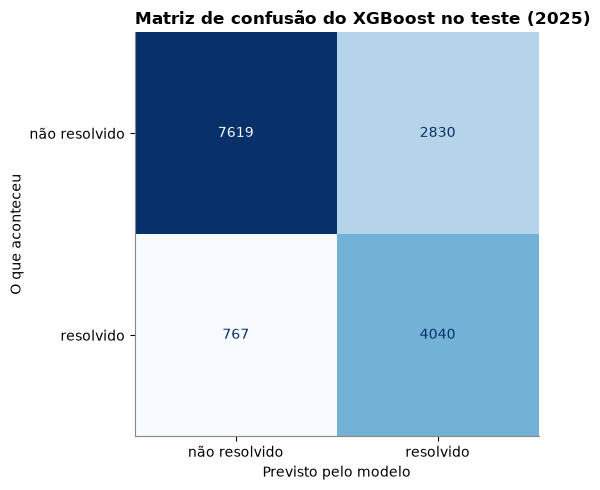

In [14]:
fig, eixo = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, xgb.predict(X_teste),
    display_labels=['não resolvido', 'resolvido'], cmap='Blues', colorbar=False, ax=eixo,
)
eixo.grid(False)
eixo.set_xlabel('Previsto pelo modelo')
eixo.set_ylabel('O que aconteceu')
eixo.set_title('Matriz de confusão do XGBoost no teste (2025)', loc='left')
fig.tight_layout()
plt.show()

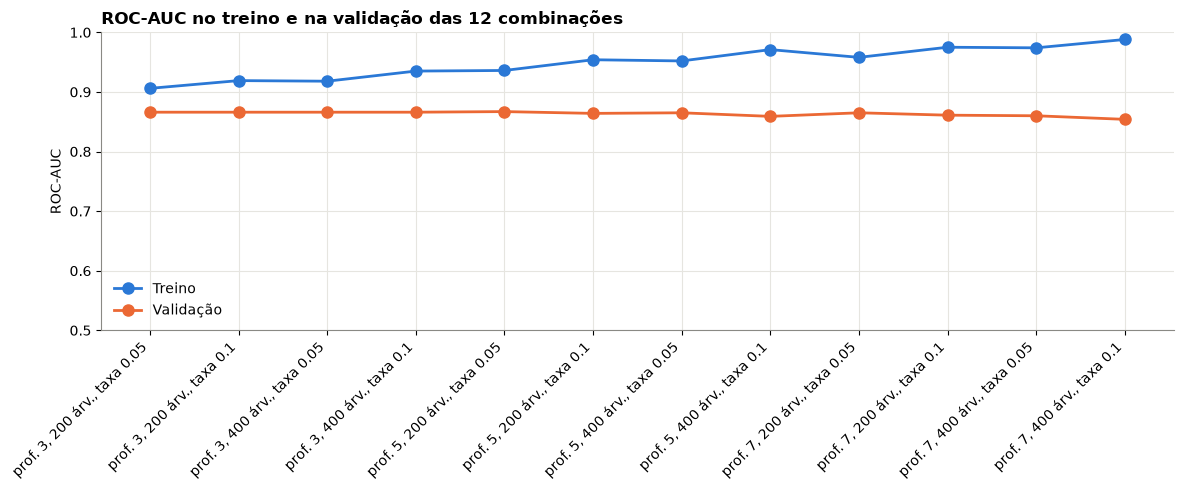

In [15]:
ordem = combinacoes.sort_values(['max_depth', 'n_estimators', 'learning_rate']).reset_index(drop=True)
rotulos = [f'prof. {p}, {n} árv., taxa {t}' for p, n, t in zip(ordem['max_depth'], ordem['n_estimators'], ordem['learning_rate'])]

fig, eixo = plt.subplots(figsize=(12, 5))
eixo.plot(rotulos, ordem['ROC-AUC treino'], color=AZUL, linewidth=2, marker='o', markersize=8, label='Treino')
eixo.plot(rotulos, ordem['ROC-AUC validação'], color=LARANJA, linewidth=2, marker='o', markersize=8, label='Validação')
eixo.set_title('ROC-AUC no treino e na validação das 12 combinações', loc='left')
eixo.set_ylabel('ROC-AUC')
eixo.set_ylim(0.5, 1)
eixo.legend(frameon=False)
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
plt.show()

O gráfico de importância soma as colunas do one-hot de cada variável. Isso favorece variáveis com muitas categorias, como a subprefeitura (32 colunas) contra o serviço (5). Por isso só dá para dizer que o lugar e o tipo de serviço são o que mais pesam, e não qual dos dois pesa mais.

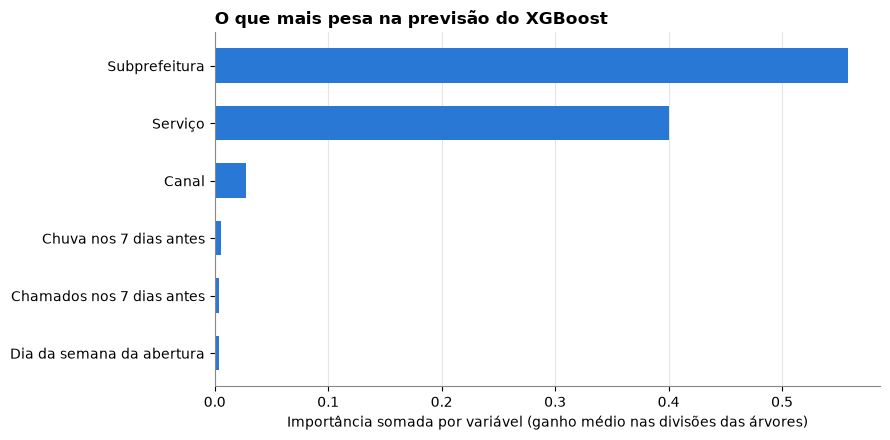

In [16]:
NOMES_VARIAVEIS = {
    'servico': 'Serviço', 'subprefeitura': 'Subprefeitura', 'canal': 'Canal',
    'dia_semana_abertura': 'Dia da semana da abertura', 'chamados_7d': 'Chamados nos 7 dias antes',
    'chuva_7d_mm': 'Chuva nos 7 dias antes',
}
origem = [coluna.split('_')[0] if coluna.startswith(('servico_', 'subprefeitura_', 'canal_')) else coluna
          for coluna in X_treino.columns]
importancia = (pd.Series(xgb.feature_importances_, index=origem)
                 .groupby(level=0).sum()
                 .rename(index=NOMES_VARIAVEIS)
                 .sort_values())

fig, eixo = plt.subplots(figsize=(9, 4.5))
eixo.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
eixo.set_title('O que mais pesa na previsão do XGBoost', loc='left')
eixo.set_xlabel('Importância somada por variável (ganho médio nas divisões das árvores)')
eixo.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

No último gráfico a probabilidade prevista foi corrigida. O XGBoost treinou dando mais peso aos resolvidos, então as probabilidades dele saem altas demais. A correção tira esse peso, e aí dá para comparar com a porcentagem real.

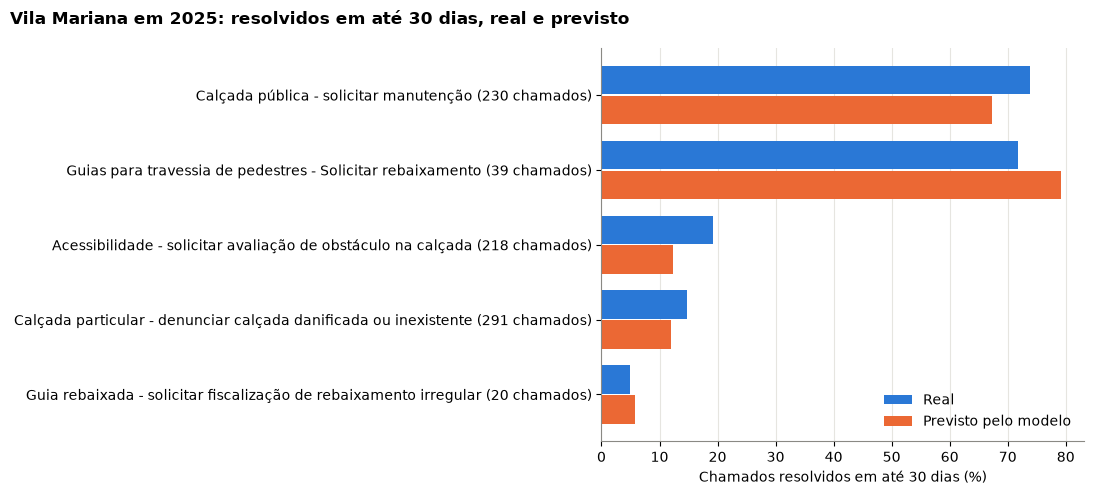

Resolvidos em até 30 dias em 2025: cidade 31.5 % | Vila Mariana 35.6 %


,chamados,real,previsto
servico,,,
Guia rebaixada - solicitar fiscalização de rebaixamento irregular,20,5.0,5.8
Calçada particular - denunciar calçada danificada ou inexistente,291,14.8,12.0
Acessibilidade - solicitar avaliação de obstáculo na calçada,218,19.3,12.3
Guias para travessia de pedestres - Solicitar rebaixamento,39,71.8,79.2
Calçada pública - solicitar manutenção,230,73.9,67.3


In [17]:
teste = base[~no_treino].copy()
prob_modelo = xgb.predict_proba(X_teste)[:, 1]
teste['prob_corrigida'] = prob_modelo / (prob_modelo + peso * (1 - prob_modelo))

vm = (teste[teste['subprefeitura'] == 'VILA MARIANA']
      .groupby('servico')
      .agg(chamados=('resolvido_30d', 'size'), real=('resolvido_30d', 'mean'), previsto=('prob_corrigida', 'mean'))
      .sort_values('real'))

posicoes = np.arange(len(vm))
fig, eixo = plt.subplots(figsize=(11, 5))
eixo.barh(posicoes + 0.2, vm['real'] * 100, height=0.38, color=AZUL, label='Real')
eixo.barh(posicoes - 0.2, vm['previsto'] * 100, height=0.38, color=LARANJA, label='Previsto pelo modelo')
eixo.set_yticks(posicoes)
eixo.set_yticklabels([f'{s} ({n} chamados)' for s, n in zip(vm.index, vm['chamados'])])
eixo.set_xlabel('Chamados resolvidos em até 30 dias (%)')
fig.suptitle('Vila Mariana em 2025: resolvidos em até 30 dias, real e previsto', x=0.01, ha='left', fontweight='bold', fontsize=12)
eixo.grid(axis='y', visible=False)
eixo.legend(frameon=False, loc='lower right')
fig.tight_layout()
plt.show()

print('Resolvidos em até 30 dias em 2025: cidade', round(y_teste.mean() * 100, 1), '% | Vila Mariana',
      round(teste[teste['subprefeitura'] == 'VILA MARIANA']['resolvido_30d'].mean() * 100, 1), '%')
vm.assign(real=(vm['real'] * 100).round(1), previsto=(vm['previsto'] * 100).round(1))

### Conclusão

Em 2025, só 31,5% dos chamados de calçada, obstáculo e rampa da cidade foram resolvidos em até 30 dias. Na Vila Mariana foi um pouco melhor, 35,6%. A grande diferença está no tipo de problema. Manutenção de calçada pública e rebaixamento de guia para travessia costumam ser resolvidos no prazo (74% e 72% na Vila Mariana). Já obstáculo na calçada, calçada particular danificada e fiscalização de rebaixamento irregular quase nunca são (19%, 15% e 5%). O modelo aprende principalmente essa diferença entre tipos de serviço e regiões. Chuva, fila de pedidos e dia da semana quase não influenciam.

O maior valor do modelo está em mostrar quais pedidos ficam parados. No app, isso vira um aviso simples, como "esse tipo de problema costuma levar mais de 30 dias; se o obstáculo na calçada estava lá semana passada, provavelmente ainda está". Esses números também servem de prova para cobrar a Prefeitura.

O erro mais perigoso é o modelo dizer que um chamado foi resolvido quando não foi. Isso aconteceu com 2.830 chamados em 2025, 27% dos não resolvidos. Quando o modelo diz que um chamado vai ser resolvido, ele acerta só 59% das vezes. Para quem usa cadeira de rodas, é confiar que a calçada foi arrumada e encontrar o problema lá. Por isso, no app, o aviso deve ser cauteloso, e a confirmação vem dos relatos de quem passou pelo lugar.

O modelo tem limites. "Finalizada" quer dizer que a Prefeitura encerrou o chamado, não que a calçada foi consertada. O 2º trimestre de 2024 ficou fora do treino. E chamados não são o mesmo que problemas, porque um mesmo buraco pode ter vários chamados ou nenhum. Na Vila Mariana, a fiscalização de rebaixamento teve só 20 chamados em 2025, então essa porcentagem é pouco confiável.

Os dados públicos respondem só parte da pergunta do app. Como é o lugar por dentro e se deu certo para outras famílias, só a comunidade sabe. Quando o app tiver esses relatos, o mesmo processo de treino pode ser usado para prever "vai dar certo pra mim?".